In [1]:
Parallel = True # default True. use False only for debug
NProc = 6 if Parallel else 1 # 6 seems optimal for desktop with 64GB RAM
import ipyparallel as ipp
cluster = ipp.Cluster(controller_ip="*", engines="mpi", n=NProc)
client = cluster.start_and_connect_sync()
view = client[:]
view.push(dict(Parallel=Parallel,NProc=NProc))
# view.activate()

Starting 6 engines with <class 'ipyparallel.cluster.launcher.MPIEngineSetLauncher'>


  0%|          | 0/6 [00:00<?, ?engine/s]

<AsyncResult(_push): pending>

In [2]:
%%px
    import numpy as np
    import sys,os
    import scipy.special as sysp
    import scipy.signal as sysig
    import scipy.linalg as linalg
    from pathlib import Path

    Base_Dir = './' # assuming we are in zeldovich-smearing/examples/, else modify this
    Like_Dir = Base_Dir + '../code/'
    sys.path.append(Like_Dir)

    from mpi4py import MPI

    from paths import *
    sys.path.append(ML_Path)
    from mlalgos import BiSequential
    from mllib import Utilities

    import copy,pickle,json

    import gc
    from time import time

    ut = Utilities()

In [3]:
%%px
    # These imports needed for MCMC using Cobaya
    from cobaya.run import run
    from cobaya.log import LoggedError


In [4]:
%%px --targets 0
    import matplotlib.pyplot as plt
    from matplotlib import gridspec
    import matplotlib as mpl
    import matplotlib.colors as pltcol

    from cobaya.model import get_model

    from getdist.mcsamples import loadMCSamples,MCSamples
    %matplotlib inline  
    import getdist.plots as gdplt
    from getdist.gaussian_mixtures import GaussianND

    mpl.rcParams['xtick.direction'] = 'in'
    mpl.rcParams['ytick.direction'] = 'in'
    mpl.rcParams['xtick.top'] = True
    mpl.rcParams['ytick.right'] = True
    mpl.rcParams['xtick.labelsize'] = 16
    mpl.rcParams['ytick.labelsize'] = 16
    mpl.rcParams['axes.labelsize'] = 18
    mpl.rcParams['legend.fontsize'] = 16 # 14
    mpl.rcParams['legend.labelspacing'] = 0.25

    FS = 18
    FS2 = 15
    FS3 = 13
    FSL = 22

    mpl.rcParams['xtick.major.size'] = 6
    mpl.rcParams['xtick.minor.size'] = 3
    mpl.rcParams['ytick.major.size'] = 6
    mpl.rcParams['ytick.minor.size'] = 3
    print('mpl setup done')
    #mpl.rcParams.keys()

[stdout:0] mpl setup done


***
# BAO Multipole Models
### Analysis of Zel'dovich smearing model with scale-dependent bias and mode coupling
***

## Setup

### Files and folders

In [5]:
%%px
    Sample = 'Euclid-ELG' # '','DESI-LRG2','Euclid-ELG'
    Model_AP = True
    Iteration = 2

    config_dict = {'DESI-LRG2': {'redshift':0.80,'Mmin':8e12,'phase':0,
                                 'sample_root':'AbacusSummit/base_c000/'},
                   'Euclid-ELG':{'redshift':1.10,'Mmin':1e12,'phase':9,
                                 'sample_root':'AbacusSummit/base_c000/'},
                   '':{'redshift':0.7,'Mmin':None,'phase':None,
                       'sample_root':'SDBMC'}}

    Redshift = config_dict[Sample]['redshift'] # 0.8 if Sample != '' else 0.7
    M_min = config_dict[Sample]['Mmin']
    Sample_Root = config_dict[Sample]['sample_root']

    # Mmin_dict = {'DESI-LRG2':8e12,
    #              # below are existing tests with 3x DESI volume
    #              'DESI-LRG2-AP-x3':8e12 if Redshift > 0.5 else 1.25e13,
    #              'DESI-LRG2-noAP-x3':8e12 if Redshift > 0.5 else 1.25e13}
    # M_min = Mmin_dict[Sample]
    
    Data_Dir = Base_Dir + 'data/'
    
    File_Tail = 'lgMmin{0:.2f}_z{1:.3f}'.format(np.log10(M_min),Redshift) if Sample != '' else 'sdbmc'
    
    if File_Tail == 'sdbmc':
        Model_AP = False # no AP distortions for sdbmc toy model
        Iteration = 2    # no iterations needed for sdbmc toy model
        
    Plots_Dir = Base_Dir + 'plots/'
    Plots_Dir += Sample_Root + Sample + '/'
    Path(Plots_Dir).mkdir(parents=True,exist_ok=True) # folder to store plots

    # Basis_Root imported from paths
    Basis_Prior_File = Basis_Root + 'fitcoeffs/biNN2p-LGbs.json'
    Cosmo_Prior_File = Basis_Root + 'fitcoeffs/biNN2p-cosmo-s.json'
    
    # don't change default values
    Include_Sig2Obs = True 
    L_Max = 3
    
    File_Body = '_LMax{0:d}_'.format(L_Max) + File_Tail
    Scales_File = Data_Dir + Sample_Root + Sample + '/xi' + File_Body + '_scales.txt'
    
    Data_File_Xi = Data_Dir + Sample_Root + Sample + '/xi' + File_Body + '.txt'
    Data_File_XiLin = Data_Dir + Sample_Root + Sample + '/xilin.txt'
    Cov_File = Data_Dir + Sample_Root + Sample + '/covmat' + File_Body 
    if Include_Sig2Obs:
        Data_File_Sig2Obs = Data_Dir + Sample_Root + Sample + '/Sig2obs' + File_Body + '.txt'
        Data_File = copy.deepcopy([Data_File_Sig2Obs,Data_File_Xi])
        Cov_File += '_inclSig2obs'
    else:
        Data_File = Data_File_Xi
    if Model_AP:
        Cov_File += '_AP'
    Cov_File += '.txt' if Iteration >= 2 else '_iter{0:d}.txt'.format(Iteration)

    if MPI.COMM_WORLD.Get_rank() == 0:
        print('')
        print('      Plots dir   : ',Plots_Dir)
        print('    Scales file   :',Scales_File)
        print('      Data file   : ',Data_File)
        print('   Cov mat file   : ',Cov_File)
        print('Data file (xi_lin): ',Data_File_XiLin)

[stdout:0] 
      Plots dir   :  ./plots/AbacusSummit/base_c000/Euclid-ELG/
    Scales file   : ./data/AbacusSummit/base_c000/Euclid-ELG/xi_LMax3_lgMmin12.00_z1.100_scales.txt
      Data file   :  ['./data/AbacusSummit/base_c000/Euclid-ELG/Sig2obs_LMax3_lgMmin12.00_z1.100.txt', './data/AbacusSummit/base_c000/Euclid-ELG/xi_LMax3_lgMmin12.00_z1.100.txt']
   Cov mat file   :  ./data/AbacusSummit/base_c000/Euclid-ELG/covmat_LMax3_lgMmin12.00_z1.100_inclSig2obs_AP.txt
Data file (xi_lin):  ./data/AbacusSummit/base_c000/Euclid-ELG/xilin.txt


### Priors, ground truth and fiducial values

In [6]:
%%px
    Prior_Signific = 10.0 # 6.0/10.0 (see Appendix D of arXiv:2602.14533)
    
    fv_prior = [0.26,Prior_Signific*0.009] # [0.26,Prior_Signific*0.009] 
    if Model_AP:
        Daiso_gt = 6.923e-4 if Sample=='DESI-LRG2' else 8.734e-4
        DaAP_gt = -5.948e-4 if Sample=='DESI-LRG2' else -6.822e-4
        # Daiso_prior = [0.0,Prior_Signific*0.0157] 
        DaAP_prior =  [0.0,Prior_Signific*0.0097] 
        
    b_dict = {'':2.435,'DESI-LRG2':2.383,'Euclid-ELG':1.775}
    f_dict = {'':0.81735,'DESI-LRG2':0.83891,'Euclid-ELG':0.88902}
    growth_dict = {'':0.6965,'DESI-LRG2':0.66476,'Euclid-ELG':0.58168}
    sigv_dict = {'':4.13,'DESI-LRG2':3.8696,'Euclid-ELG':3.3860}
    rLP_dict = {'':93.1636,'DESI-LRG2':93.0358,'Euclid-ELG':93.0358}
    rZC_dict = {'':120.5840,'DESI-LRG2':120.6466,'Euclid-ELG':120.6466}

    DV_dict = {'':None,'DESI-LRG2':1781.2562,'Euclid-ELG':2185.6239} # DV = (z*(c/H)*DM**2)**(1/3)
    DV_gt = DV_dict[Sample]

    DVfid_dict = {'':None,'DESI-LRG2':1782.4893,'Euclid-ELG':2187.5328} # DV = (z*(c/H)*DM**2)**(1/3)
    DV_fid = DV_dict[Sample]

    
    # DESI-LRG2
    # ... alpha_par : 1 + 1.089e-03
    # ... alpha_perp: 1 + 4.939e-04
    # ...  DaAP: -5.948e-04
    # ... Daiso: +6.923e-04
    # ...     DV: 1781.2562 Mpc/h_fid
    # ... DV_fid: 1782.4893 Mpc/h_fid
    
    # Euclid-ELG
    # ... alpha_par : 1 + 1.329e-03
    # ... alpha_perp: 1 + 6.458e-04
    # ...  DaAP: -6.822e-04
    # ... Daiso: +8.734e-04
    # ...     DV: 2185.6239 Mpc/h_fid
    # ... DV_fid: 2187.5328 Mpc/h_fid


    rLP_gt = rLP_dict[Sample]
    rZC_gt = rZC_dict[Sample]

    b_gt = b_dict[Sample]
    b_prior = [b_gt,0.05*b_gt]
    
    # below values in c000 cosmology 
    growth_gt = growth_dict[Sample] # D(z)/D(0) 
    f_gt = f_dict[Sample] # f(z) = dlnD/dlna 
    beta_gt = f_gt/b_gt
    sigv_gt = sigv_dict[Sample] # Mpc/h_fid

    # # DELETE BELOW
    # growth_fid = 1.0*growth_gt
    # f_fid = 1.0*f_gt
    # sigv_fid = 1.0*sigv_gt

    # below values in fiducial Planck18 cosmology of arXiv:2602.14533
    f_fid_dict = {'':0.81735,'DESI-LRG2':0.83981,'Euclid-ELG':0.88968}
    growth_fid_dict = {'':0.6965,'DESI-LRG2':0.66427,'Euclid-ELG':0.58118}
    sigv_fid_dict = {'':4.13,'DESI-LRG2':3.9407,'Euclid-ELG':3.4478}
    b_fid = 1.0*b_gt
    growth_fid = growth_fid_dict[Sample] # D(z)/D(0) 
    f_fid = f_fid_dict[Sample] # f(z) = dlnD/dlna 
    beta_fid = f_fid/b_fid
    sigv_fid = sigv_fid_dict[Sample] # Mpc/h_fid
    sigma_fid = np.sqrt(2)*sigv_fid # Mpc/h_fid; sqrt(2) to satisfy physical prior R*^2 >= 0

    if MPI.COMM_WORLD.Get_rank() == 0:
        xilin_true = np.loadtxt(Data_File_XiLin).T
        xilin_true[1] *= growth_gt**2 # since stored value was at z=0
    

### Basis selection

In [7]:
%%px
    # Use_Basis = np.array([0,1,3,5,7,8]) 
    Use_Basis = np.arange(9)
    N_Basis = len(Use_Basis)

    if MPI.COMM_WORLD.Get_rank() == 0:
        print('Using {0:d} basis functions:'.format(N_Basis))
        print(Use_Basis)

    with open(Basis_Prior_File,'rb') as f:
        basis_prior = json.load(f)

    for key in basis_prior.keys():
        basis_prior[key][1] *= Prior_Signific/(5.0*np.sqrt(12)) 
        # file was historically saved with significance 5.0*sqrt(12), convert to requested value
        # will later get multiplied by (b_fid*growth_fid)^2

    if MPI.COMM_WORLD.Get_rank() == 0:
        print('Basis prior [mean,std] from distribution:')
        print(basis_prior)
    
        print('... done')

[stdout:0] Using 9 basis functions:
[0 1 2 3 4 5 6 7 8]
Basis prior [mean,std] from distribution:
{'0': [0.0023611646092524534, np.float64(0.008724152801539464)], '1': [-0.00480206477496199, np.float64(0.01165494582255631)], '2': [-0.003615273200665197, np.float64(0.003443656009977538)], '3': [0.006376316111497617, np.float64(0.005599415658679356)], '4': [0.0024964699762593267, np.float64(0.005204474408053529)], '5': [0.007156065134415753, np.float64(0.009444695139140492)], '6': [-0.00685157000880762, np.float64(0.005465951824593434)], '7': [0.0026892945537788397, np.float64(0.013342909727103164)], '8': [0.007288963307259968, np.float64(0.005600936312801435)]}
... done


[stdout:0] Setting up 20,6 layer feed-forward bi-neural network
... ... expecting data dim = 1, theta dim = 2, output dim = 1
... ... NNa using hidden layers of sizes [8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8]
... ... ... and activations [relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,tanh,tanh,tanh,tanh,tanh]
... ... NNw using hidden layers of sizes [3,3,3,3,3,9]
... ... ... and activations [tanh,tanh,tanh,tanh,tanh,tanh]
... ... using loss function 'square'
... ... not using any regularization
... ... not using any weight decay in NNa
... ... not using any weight decay in NNw
... extracting basis functions from NNa
... setting up 20 layer feed-forward neural network
Warning!: last activation tanh seems inconsistent with square loss. Proceed with caution!
... ... expecting data dim = 1, target dim = 8
... ... using hidden layers of sizes [8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8]
... ... ... and activations [relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,rel

[output:0]

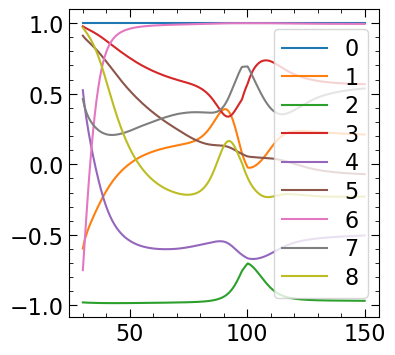

In [8]:
%%px --targets 0
    # read setup parameters
    with open(Basis_Stem + '.pkl', 'rb') as f:
        params_setup = pickle.load(f)    
    params_setup['file_stem'] = Basis_Stem
    # initialize class
    binet = BiSequential(params=params_setup)
    # load network parameters from files
    binet.load()

    rvals = np.linspace(30,150,500)

    basis = binet.extract_basis()
    basis_func = basis.predict(binet.rv(rvals))
    basis_func = np.concatenate((np.ones((1,basis_func.shape[1])),basis_func),axis=0) 
    basis_func = basis_func[Use_Basis]

    plt.figure(figsize=(4,4))
    for b in range(N_Basis):
        plt.plot(rvals,basis_func[b],label=str(Use_Basis[b]))
    plt.minorticks_on()
    plt.legend()
    plt.show()

## MCMC 

### Info dictionary definition

In [9]:
%%px
    Rescale = 1e3
    Modify_Data = True # default True
    VaryMC = True # default True

    Accuracy = 'mid' # 'low','mid' or 'high'. Default 'mid', giving <~3% error on quadrupole

    id_str = Sample_Root + Sample + '/mcmc' + File_Body
    if Include_Sig2Obs:
        id_str += '_inclSig2obs'
    if not Modify_Data:
        id_str += '_unmod'
    if Accuracy != 'mid':
        id_str += '_'+Accuracy+'acc'
    id_str += '_mpi' # this is mpi notebook
    if L_Max < 3:
        id_str += '_LMax{0:d}'.format(L_Max)
        
    Run_Cobaya = False
    Resume = False

    Max_Samples = 10000000 
    Rminus1_Stop = 0.01 # 0.01
    Rminus1_CL_Stop = 0.035 # 0.05; arXiv:2602.14533 used 0.035/0.04
    Rminus1_CL_Level = 0.95 # 95

    Burn_In = 0

    info = {}
    info['likelihood'] = {'zelsmear.ZeldovichSmearingLike':
                          {'python_path':Like_Dir,
                           'rescale':Rescale,
                           'L_Max':L_Max,
                           'modify_data':Modify_Data,
                           'include_Sig2obs':Include_Sig2Obs,
                           'scales_file':Scales_File,
                           'data_file':Data_File,
                           'cov_file':Cov_File
                          }}

    info['theory'] = {'zelsmear.ZeldovichSmearingTheory':
                      {'python_path':Like_Dir,
                       'stop_at_error': True,
                       'use_basis': Use_Basis,
                       'basis_stem':Basis_Stem,
                       'accuracy':Accuracy,
                       'n_r':100, 
                       # 100 gives LP convergence error ~0.1%, i.e. 3x smaller than DESI expectation
                       # 300 gives ~0.03%, 1000 is converged
                       'scales_file':Scales_File,
                       'L_Max':L_Max,
                       'modify_data':Modify_Data,
                       'model_AP':Model_AP,
                       'include_Sig2obs':Include_Sig2Obs
                      }}

    W_Names = ['w_{0:d}'.format(m) for m in Use_Basis] 

    Params_List = ['beta','sigv']
    Latex_List = ['\\beta','\\sigma_{\\rm v}']
    Defaults_List = [beta_fid,sigv_fid]
    proposal_list = [5e-3,5e-3]

    Params_List.extend(W_Names)
    Latex_List.extend(W_Names)
    for w in range(len(W_Names)):
        Defaults_List.append((b_fid*growth_fid)**2*basis_prior[str(w)][0])
    proposal_list.extend([5e-4]*N_Basis)

    Params_List += ['b','B1st','Bvst','sigma','AMC']
    Latex_List += ['b','B_{1\\ast}','B_{v\\ast}','\\sigma','A_{\\rm MC}']
    Defaults_List += [b_fid,0.0,0.0,sigma_fid,0.0] 
    proposal_list += [1e-3,1e-2,3e-3,5e-3,5e-3]

    if L_Max > 1:
        Params_List += ['qbar2']
        Latex_List += ['\\bar q^{(2)}']
        Defaults_List += [0.0] 
        proposal_list += [None] if (Modify_Data & (L_Max == 2)) else [2e-4 if Sample != 'Euclid-ELG' else 3e-5]
        if L_Max == 3:
            Params_List += ['qbar4']
            Latex_List += ['\\bar q^{(4)}']
            Defaults_List += [0.0] 
            proposal_list += [None] if Modify_Data else [2e-4 if Sample != 'Euclid-ELG' else 3e-5]

    if Include_Sig2Obs:
        Params_List += ['fv']
        Latex_List += ['f_{\\rm v}']
        Defaults_List += [fv_prior[0]]  
        proposal_list += [1e-4]

    if Model_AP:
        Params_List += ['DaAP']
        Latex_List += ['\\Delta\\alpha_{\\rm AP}']
        Defaults_List += [DaAP_prior[0]]  
        proposal_list += [5e-4]
        # Params_List += ['Daiso','DaAP']
        # Latex_List += ['\\Delta\\alpha_{\\rm iso}','\\Delta\\alpha_{\\rm AP}']
        # Defaults_List += [Daiso_prior[0],DaAP_prior[0]]  
        # proposal_list += [5e-4,5e-4]
        
    Derived_List = ['peak','LP','ZC']
    Derived_Latex = ['r_{\\rm peak}','r_{\\rm LP}','r_{\\rm ZC}']
    Derived_List = ['f'] + Derived_List
    Derived_Latex = ['f'] + Derived_Latex

    Delta_param = 0.001 # percentage variation for reference point

    info['params'] = {}
    for p in range(len(Params_List)):
        param = Params_List[p]
        proposal = proposal_list[p]
        defval = Defaults_List[p]
        
        info['params'][param] = {'ref':{'min':defval-Delta_param*(1.0 if param[0] in ['D','B'] else np.fabs(defval)),
                                        'max':defval+Delta_param*(1.0 if param[0] in ['D','B'] else np.fabs(defval))},
                                 'proposal':proposal,'latex':Latex_List[p]}
        if param == 'AMC':
            if VaryMC:
                info['params'][param] = {'ref':{'min':0.0,#defval-Delta_param*np.fabs(defval),
                                                'max':Delta_param},#defval+Delta_param*np.fabs(defval)},
                                         'proposal':proposal,'latex':Latex_List[p]}
            else:
                info['params'][param] = defval                
        if (param == 'qbar2'):
            if Modify_Data & (L_Max == 2):
                info['params'][param] = defval
            else:
                info['params'][param] = {'ref':{'min':-Delta_param,#defval-Delta_param*np.fabs(defval),
                                                'max':Delta_param},#defval+Delta_param*np.fabs(defval)},
                                         'proposal':proposal,'latex':Latex_List[p]}
        if (param == 'qbar4'):
            if Modify_Data:
                info['params'][param] = defval                
            else:
                info['params'][param] = {'ref':{'min':defval-Delta_param*np.fabs(defval),
                                                'max':defval+Delta_param*np.fabs(defval)},
                                         'proposal':proposal,'latex':Latex_List[p]}
                
    ###############################
    # set priors
    ###############################
    info['params']['beta']['prior'] = {'min':-1.0,'max':1.0} 
    info['params']['sigv']['prior'] = {'min':0.0,'max':12.0}

    for w in range(len(W_Names)):
        wname = W_Names[w]
        w_mean,w_std = basis_prior[str(w)][0],basis_prior[str(w)][1]
        w_mean *= (b_fid*growth_fid)**2
        w_std *= (b_fid*growth_fid)**2
        info['params'][wname]['prior'] = {'dist':'norm','loc':w_mean,'scale':w_std} 
        
    info['params']['b']['prior'] =  {'dist':'norm','loc':b_prior[0],'scale':b_prior[1]}
    info['params']['B1st']['prior'] = {'min':-100.0,'max':100.0}
    info['params']['Bvst']['prior'] = {'min':-100.0,'max':100.0}
    info['params']['sigma']['prior'] = {'min':0.0,'max':12.0} 
    if VaryMC:
        info['params']['AMC']['prior'] = {'dist':'norm','loc':0.0,'scale':0.05}
    if L_Max > 1:
        if (not Modify_Data) | (L_Max == 3):
            # note L_Max==3 not 2
            info['params']['qbar2']['prior'] = {'min':-2.0,# if Sample != 'Euclid-ELG' else 0.0,
                                                'max':2.0}
        if (L_Max == 3) & (not Modify_Data):
            info['params']['qbar4']['prior'] = {'min':-2.0,# if Sample != 'Euclid-ELG' else 0.0,
                                                'max':2.0}
    if Include_Sig2Obs:
        info['params']['fv']['prior'] = {'dist':'norm','loc':fv_prior[0],'scale':fv_prior[1]}

    if Model_AP:
        # info['params']['Daiso']['prior'] = {'dist':'norm','loc':Daiso_prior[0],'scale':Daiso_prior[1]}
        info['params']['DaAP']['prior'] = {'dist':'norm','loc':DaAP_prior[0],'scale':DaAP_prior[1]}

    for d in range(len(Derived_List)):
        dpar = Derived_List[d]
        info['params'][dpar] = {'latex':Derived_Latex[d]}

    info['sampler'] = {'mcmc':
                       {'learn_proposal': True,
                        'measure_speeds': True,
                        'max_samples': Max_Samples,
                        'max_tries': 1000,
                        'Rminus1_stop': Rminus1_Stop,
                        'Rminus1_cl_stop': Rminus1_CL_Stop,
                        'Rminus1_cl_level': Rminus1_CL_Level,
                        'burn_in': Burn_In}}

    info_output = 'stats/chains/' 
    info_output += 'varymc/' if VaryMC else 'nomc/'
    info_output += id_str
    info['output'] = info_output
    if Resume:
        info["resume"] = True
    else:
        info["force"] = True
        
    if MPI.COMM_WORLD.Get_rank() == 0:
        print(info['output'])
        print('Priors:')
        for key in info['params'].keys():
            if not np.isscalar(info['params'][key]):
                if 'prior' in info['params'][key].keys():
                    print(key,info['params'][key]['prior'])

[stdout:0] stats/chains/varymc/AbacusSummit/base_c000/Euclid-ELG/mcmc_LMax3_lgMmin12.00_z1.100_inclSig2obs_mpi
Priors:
beta {'min': -1.0, 'max': 1.0}
sigv {'min': 0.0, 'max': 12.0}
w_0 {'dist': 'norm', 'loc': 0.0025127211836093286, 'scale': np.float64(0.009284131850685837)}
w_1 {'dist': 'norm', 'loc': -0.005110295926776295, 'scale': np.float64(0.012403044305931784)}
w_2 {'dist': 'norm', 'loc': -0.003847327509589683, 'scale': np.float64(0.003664694689826673)}
w_3 {'dist': 'norm', 'loc': 0.006785594068268739, 'scale': np.float64(0.005958826541048275)}
w_4 {'dist': 'norm', 'loc': 0.002656711424951225, 'scale': np.float64(0.00553853511247106)}
w_5 {'dist': 'norm', 'loc': 0.007615393007363202, 'scale': np.float64(0.010050923792375452)}
w_6 {'dist': 'norm', 'loc': -0.007291353188443683, 'scale': np.float64(0.005816796035492124)}
w_7 {'dist': 'norm', 'loc': 0.002861912874589756, 'scale': np.float64(0.014199353908194382)}
w_8 {'dist': 'norm', 'loc': 0.0077568215434593605, 'scale': np.float64(0

### Run chains!

In [10]:
%%px
    if Run_Cobaya:
        start_time = time()
        comm = MPI.COMM_WORLD
        rank = comm.Get_rank()
        success = False
        try:
            upd_info, sampler = run(info,resume=Resume,allow_changes=True)
            success = True
        except LoggedError as err:
            pass
        success = all(comm.allgather(success))
        if not success and rank == 0:
            print("Sampling failed!")

        ut.time_this(start_time)
    else:
        print('Chains (hopefully) exist!')

[stdout:1] Chains (hopefully) exist!


[stdout:4] Chains (hopefully) exist!


[stdout:5] Chains (hopefully) exist!


[stdout:2] Chains (hopefully) exist!


[stdout:3] Chains (hopefully) exist!


[stdout:0] Chains (hopefully) exist!


## Plots

In [11]:
%%px --targets 0
    Save_Fig = True

[stdout:0] [0 : model] *WARNING* Ignored blocks/options: ['sampler', 'output', 'force']
Setting up 20,6 layer feed-forward bi-neural network
... ... expecting data dim = 1, theta dim = 2, output dim = 1
... ... NNa using hidden layers of sizes [8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8]
... ... ... and activations [relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,relu,tanh,tanh,tanh,tanh,tanh]
... ... NNw using hidden layers of sizes [3,3,3,3,3,9]
... ... ... and activations [tanh,tanh,tanh,tanh,tanh,tanh]
... ... using loss function 'square'
... ... not using any regularization
... ... not using any weight decay in NNa
... ... not using any weight decay in NNw
Extracting basis functions as NN...
... extracting basis functions from NNa
... setting up 20 layer feed-forward neural network
Warning!: last activation tanh seems inconsistent with square loss. Proceed with caution!
... ... expecting data dim = 1, target dim = 8
... ... using hidden layers of sizes [8,8,8,8,

%px:   0%|          | 0/1 [00:00<?, ?tasks/s]

[output:0]

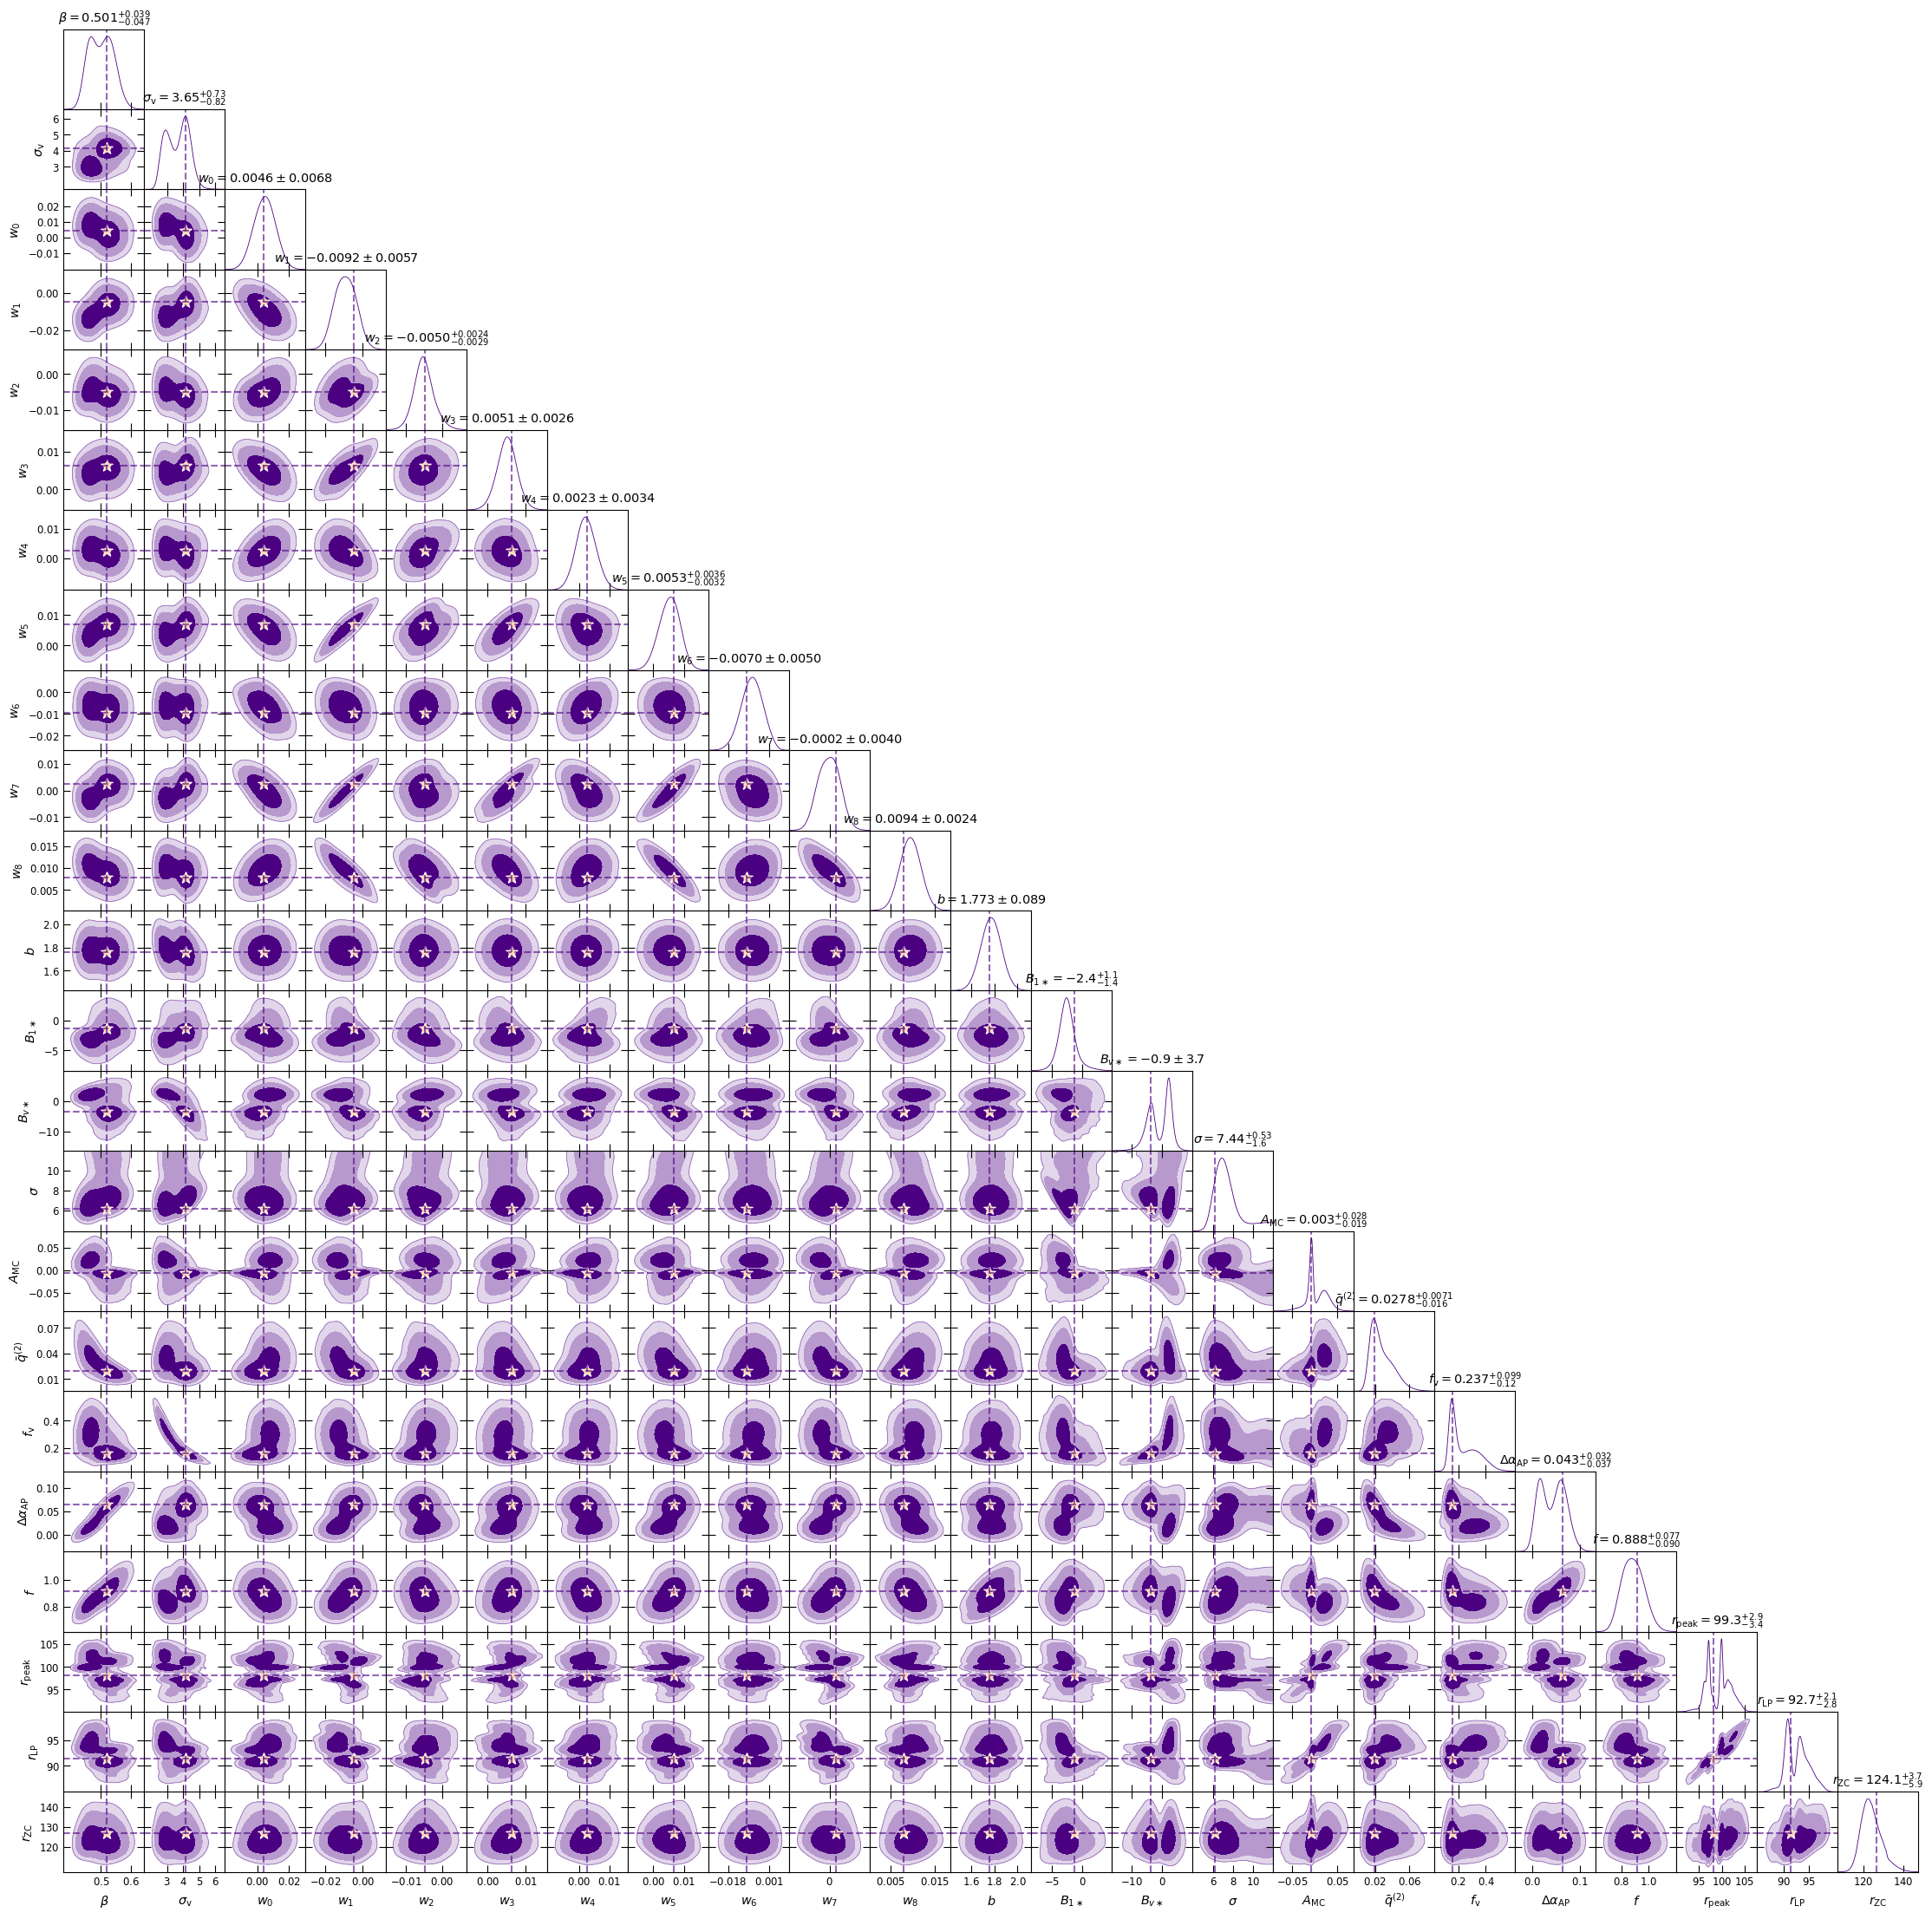

[output:0]

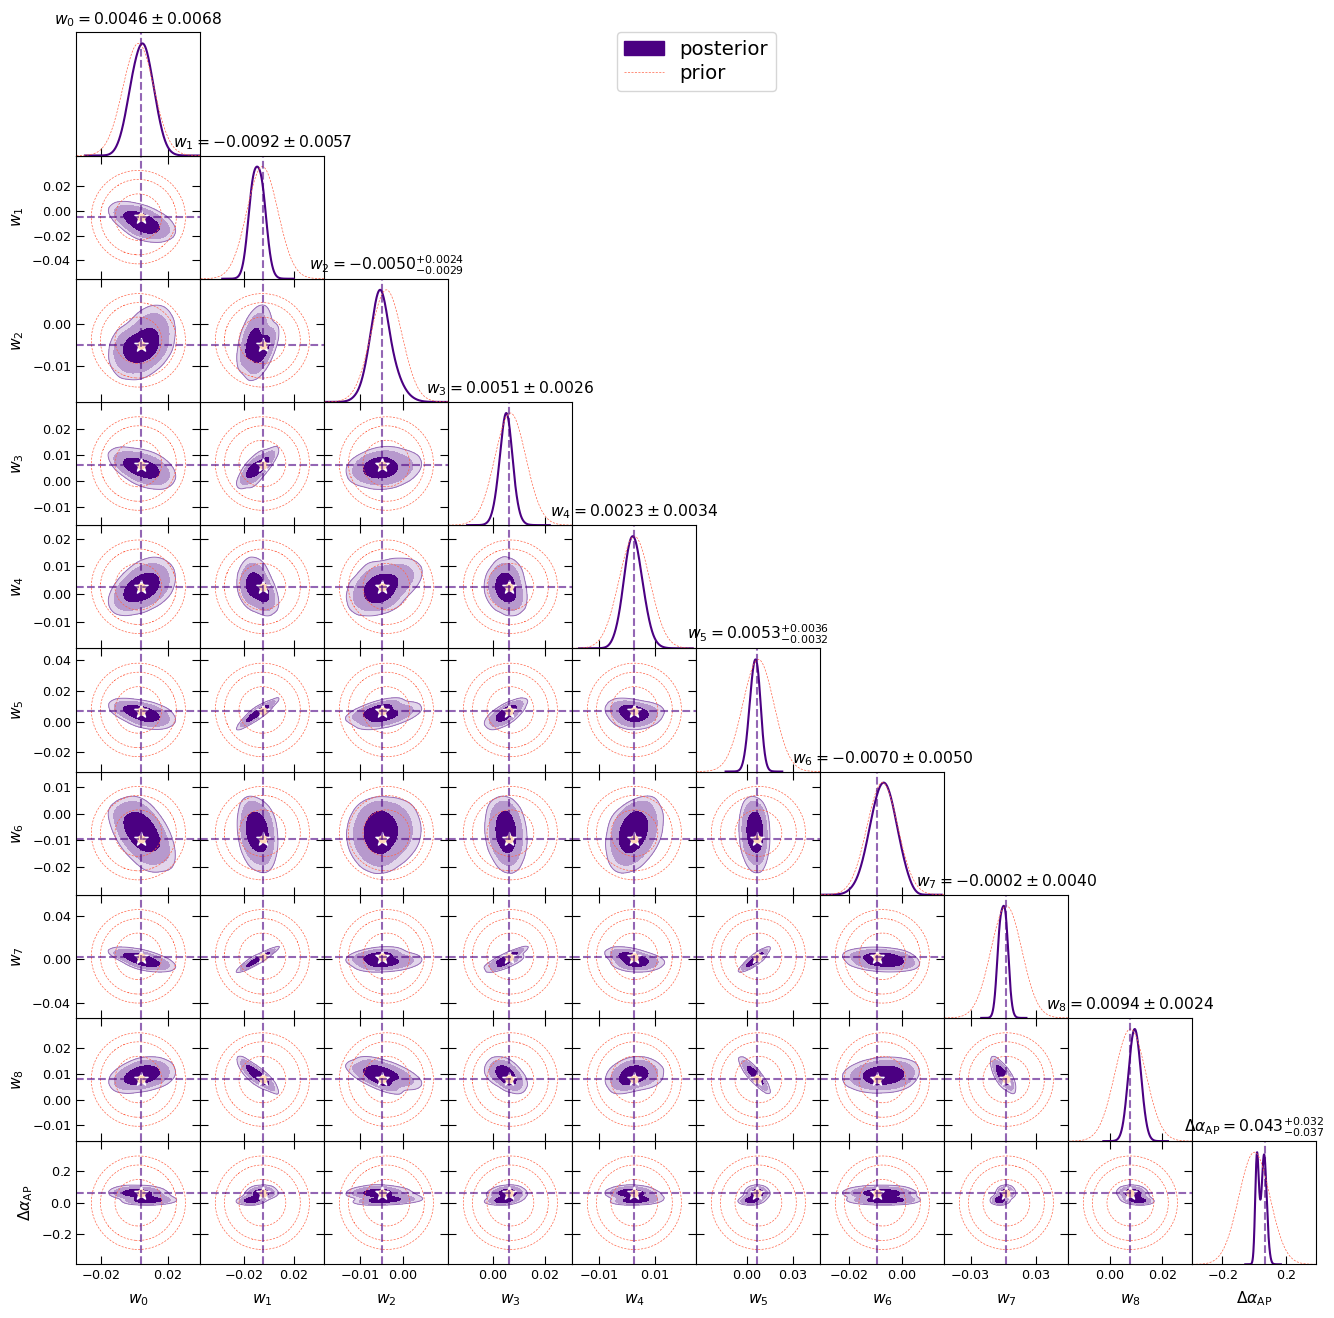

[output:0]

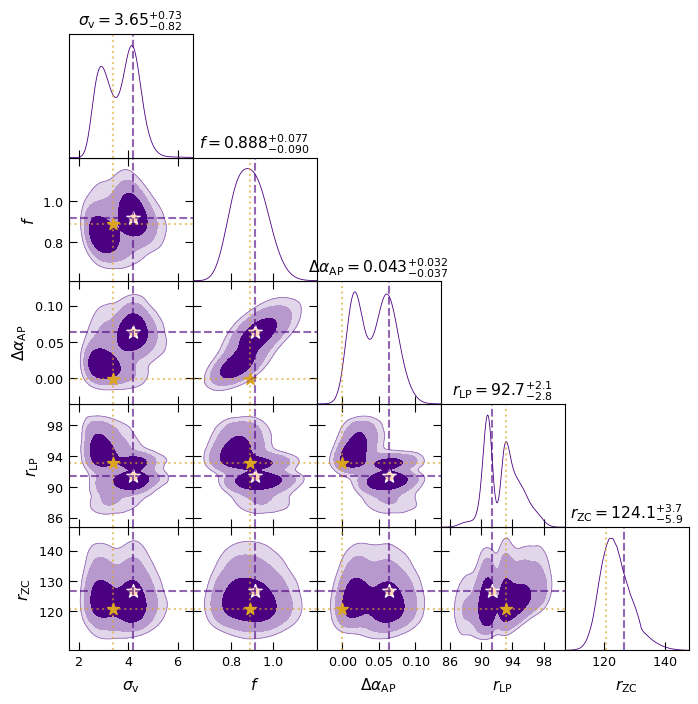

[output:0]

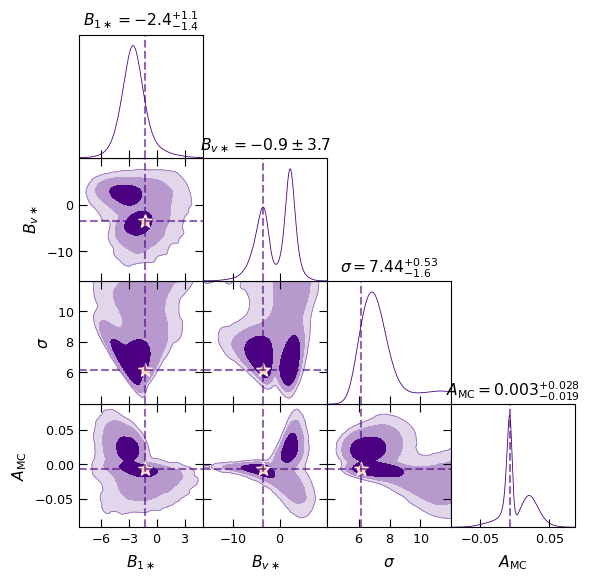

[output:0]

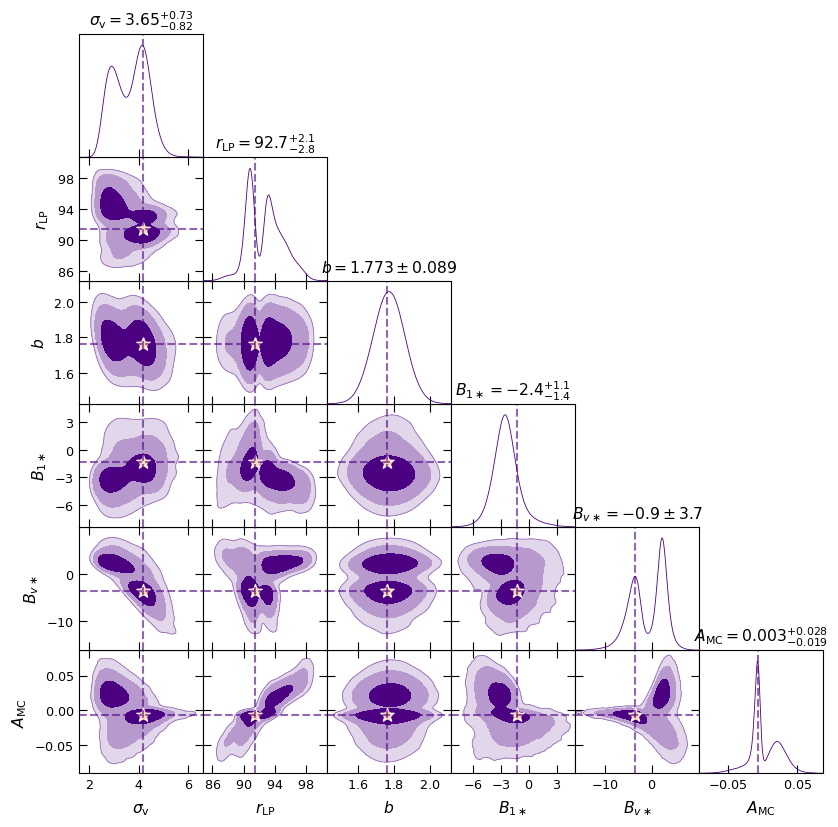

[output:0]

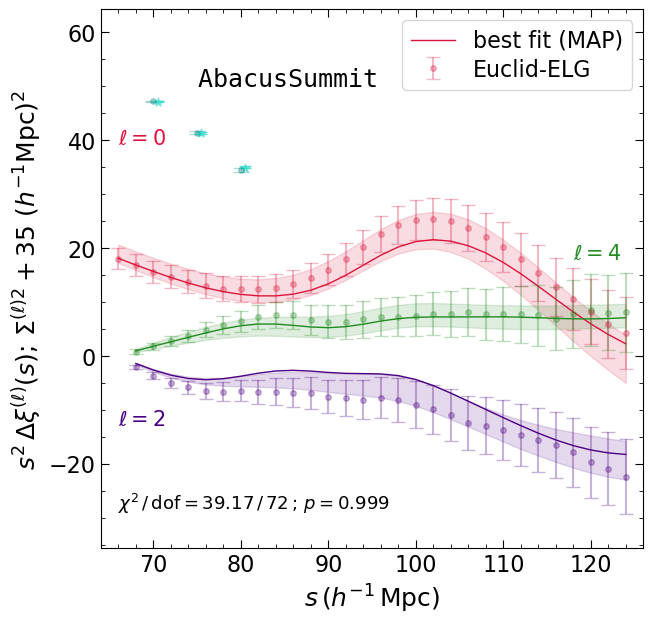

[output:0]

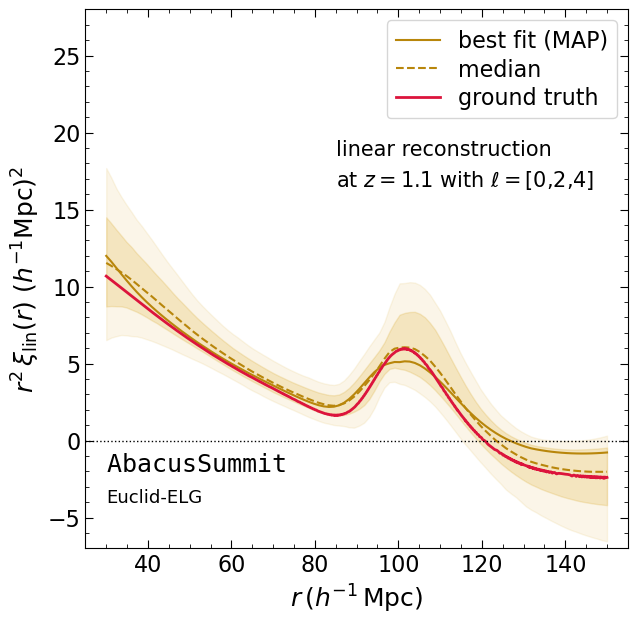

In [12]:
%%px --targets 0
    model = get_model(info)
    Burn_Frac = 0.3
    rng = np.random.RandomState(42)
    dim = N_Basis + 7
    if L_Max > 1:
        dim += 1
        if L_Max == 3:
            dim += 1
    if Include_Sig2Obs:
        dim += 1
    if Model_AP:
        dim += 1 # 2
    if not VaryMC:
        dim -= 1 # don't sample AMC
    if Modify_Data & (L_Max > 1):
            dim -= 1 # don't sample qbar2 (for L_Max==2) or qbar4 (for L_Max==3)

    Scales = np.loadtxt(Scales_File)
    Ndata = Scales.size*L_Max
    if Modify_Data & (L_Max > 1):
        Ndata -= 1
        if L_Max == 3:
            Ndata -= 1
    if Include_Sig2Obs:
        Ndata += L_Max
    dof = Ndata - dim
    print(dim,dof)        

    plot_param_list = ['beta','sigv']
    plot_param_list.extend(W_Names)
    plot_param_list += ['b','B1st','Bvst','sigma']
    if VaryMC:
        plot_param_list += ['AMC']
    if L_Max > 1:
        if (not Modify_Data) | (L_Max == 3):
            # note L_Max==3 not 2
            plot_param_list += ['qbar2']
        if (L_Max == 3) & (not Modify_Data):
            plot_param_list += ['qbar4']
    if Include_Sig2Obs:
        plot_param_list += ['fv']
    if Model_AP:
        plot_param_list += ['DaAP']
        # plot_param_list += ['Daiso','DaAP']
    plot_param_list += Derived_List

    start_time = time()

    gd_sample = loadMCSamples(os.path.abspath(info["output"]),settings={'ignore_rows':Burn_Frac})
    gd_sample.label = 'posterior'
    mcmc_covmat = gd_sample.getCovMat().matrix[:dim, :dim]

    sample = gd_sample.samples
        
    sample = sample.T
    ibest = sample[-2].argmin()
    mcmc_best = gd_sample.samples[ibest]
    mcmc_chi2 = mcmc_best[-1]
    mcmc_best = mcmc_best[:dim+len(Derived_List)].copy()
    pval = sysp.gammainc(mcmc_chi2/2,dof/2)

    mcmc_sig = np.sqrt(np.diag(mcmc_covmat))

    print('MCMC...')
    print(plot_param_list)

    offset = 2
    par_show = np.arange(len(plot_param_list)) + offset
    # par_show[-1] = -2

    sample_for_MAP = np.loadtxt(os.path.abspath(info["output"])+'.'+str(1)+'.txt')
    sample_for_MAP = sample_for_MAP[int(0.3*sample_for_MAP.shape[0]):]
    for c in range(1,NProc):
        sample_c = np.loadtxt(os.path.abspath(info["output"])+'.'+str(c+1)+'.txt')
        sample_c = sample_c[int(0.3*sample_c.shape[0]):]
        sample_for_MAP = np.concatenate((sample_for_MAP,sample_c),axis=0)
    iMAP = sample_for_MAP.T[1].argmin()
    mcmc_MAP = sample_for_MAP[iMAP][par_show]
    print("... MAP       = ( "+','.join(['%.4e' % (pval,) for pval in mcmc_MAP])+" )")
    print("... best fit  = ( "+','.join(['%.4e' % (pval,) for pval in mcmc_best])+" )")
    print("... std dev   = ( "+','.join(['%.4e' % (pval,) for pval in mcmc_sig])+" )")
    print("... chi2_best,dof,chi2_red,pval: {0:.3f},{1:d},{2:.3f},{3:.3e}".format(mcmc_chi2,dof,mcmc_chi2/dof,pval))

    ###################################################
    # All params
    Subplot_Size = 1.2
    gdplot = gdplt.get_subplot_plotter(subplot_size=Subplot_Size)
    gdplot.settings.num_plot_contours = 3
    gdplot.settings.axes_fontsize = FS3
    gdplot.settings.axes_labelsize = FS2
    gdplot.settings.title_limit_fontsize = FS2 

    gdplot.triangle_plot([gd_sample], plot_param_list,
                         filled=[True],contour_colors=['indigo'],legend_loc='upper center',
                         markers=mcmc_MAP[:dim+len(Derived_List)],
                         marker_args={'c': 'indigo','ls': '--','lw': 1.5,'alpha': 0.6},
                         title_limit=1)
    for par_y in range(dim+len(Derived_List)):
        str_y = plot_param_list[par_y]
        ax = gdplot.subplots[par_y,par_y]
        # ax.axvline(mcmc_MAP[par_y],c='indigo',ls='--',lw=1.5,alpha=0.6)
        for par_x in range(par_y):
            str_x = plot_param_list[par_x]
            ax = gdplot.subplots[par_y,par_x]
            ax.scatter([mcmc_MAP[par_x]],[mcmc_MAP[par_y]],
                       marker='*',s=100,c='white')
            ax.scatter([mcmc_best[par_x]],[mcmc_best[par_y]],
                       marker='o',s=25,c='peachpuff')

    if Save_Fig:
        filename = 'contours' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_mpi.pdf'
        print('Writing to file: '+Plots_Dir+filename)
        gdplot.export(fname=filename,adir=Plots_Dir)
        
    ###################################################
    # xilin,AP params
    xilinAP_List = copy.deepcopy(W_Names) 
    xilinAP_Inds = [2+w for w in range(len(W_Names))] 

    if Model_AP:
        xilinAP_List += ['DaAP']
        xilinAP_Inds += [-5]
        # xilinAP_List += ['Daiso','DaAP']
        # xilinAP_Inds += [-6,-5]
    xilinAP_Latex = np.array(Latex_List)[xilinAP_Inds]
        
    cprior_cov = []
    cprior_mean = []
    for key in xilinAP_List:
        mean = info['params'][key]['prior']['loc']
        std = info['params'][key]['prior']['scale']
        cprior_mean.append(mean)
        cprior_cov.append(std**2)
    cprior_cov = np.diag(cprior_cov)
    cprior = GaussianND(cprior_mean,cprior_cov,names=xilinAP_List,labels=xilinAP_Latex,label='prior')

    Subplot_Size = 1.6
    gdplot = gdplt.get_subplot_plotter(subplot_size=Subplot_Size)
    gdplot.settings.num_plot_contours = 3
    gdplot.settings.axes_fontsize = FS3
    gdplot.settings.axes_labelsize = FS2
    gdplot.settings.title_limit_fontsize = FS2 
    gdplot.settings.legend_fontsize = FS

    gdplot.triangle_plot([gd_sample,cprior],xilinAP_List,
                         filled=[True,False],
                         contour_colors=['indigo','tomato'],contour_ls=['-','--'],contour_lws=[1.5,0.5],
                         legend_loc='upper center',
                         markers=mcmc_MAP[xilinAP_Inds],
                         marker_args={'c': 'indigo','ls': '--','lw': 1.5,'alpha': 0.6},
                         title_limit=1)
    for par_y in range(len(xilinAP_List)):
        str_y = xilinAP_List[par_y]
        ax = gdplot.subplots[par_y,par_y]
        # ax.axvline(mcmc_MAP[xilinAP_Inds[par_y]],c='indigo',ls='--',lw=1.5,alpha=0.6)
        for par_x in range(par_y):
            str_x = xilinAP_List[par_x]
            ax = gdplot.subplots[par_y,par_x]
            ax.scatter([mcmc_MAP[xilinAP_Inds[par_x]]],[mcmc_MAP[xilinAP_Inds[par_y]]],
                       marker='*',s=100,c='white')
            ax.scatter([mcmc_best[xilinAP_Inds[par_x]]],[mcmc_best[xilinAP_Inds[par_y]]],
                       marker='o',s=25,c='peachpuff')

    if Save_Fig:
        filename = 'contours' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_xilinAP_mpi.pdf'
        print('Writing to file: '+Plots_Dir+filename)
        gdplot.export(fname=filename,adir=Plots_Dir)
        
    ###################################################
    # Cosmo params
    Cosmo_List = ['sigv','f'] 
    Cosmo_Inds = [1,dim] 
    Cosmo_Truth = [sigv_gt,f_gt] 
    if Model_AP:
        Cosmo_Truth[0] = Cosmo_Truth[0]*(1+Daiso_gt)
    # model predicts sigv_true/DV_true using sigv_model/DV_fid
    # so compare sigv_model with sigv_true*(DV_fid/DV_true) = sigv_true*alpha_iso = sigv_true*(1+Daiso)

    if Model_AP:
        Cosmo_List += ['DaAP']
        Cosmo_Inds += [-5]
        Cosmo_Truth += [DaAP_gt]
        # Cosmo_List += ['Daiso','DaAP']
        # Cosmo_Inds += [-6,-5]
        # Cosmo_Truth += [Daiso_gt,DaAP_gt]

    Cosmo_List += ['LP','ZC']
    Cosmo_Inds += [-2,-1]
    Cosmo_Truth += [rLP_gt,rZC_gt]
    if Model_AP:
        Cosmo_Truth[-1] = Cosmo_Truth[-1]*(1+Daiso_gt)
        Cosmo_Truth[-2] = Cosmo_Truth[-2]*(1+Daiso_gt)

    # model predicts r_true/DV_true using r_model/DV_fid
    # so compare r_model with r_true*(DV_fid/DV_true) = r_true*alpha_iso = r_true*(1+Daiso)

    print(Cosmo_List,Cosmo_Truth)

    Subplot_Size = 1.6
    gdplot = gdplt.get_subplot_plotter(subplot_size=Subplot_Size)
    gdplot.settings.num_plot_contours = 3
    gdplot.settings.axes_fontsize = FS3
    gdplot.settings.axes_labelsize = FS2
    gdplot.settings.title_limit_fontsize = FS2 

    gdplot.triangle_plot([gd_sample],Cosmo_List,
                         filled=[True],contour_colors=['indigo'],legend_loc='upper center',
                         markers=mcmc_MAP[Cosmo_Inds],
                         marker_args={'c': 'indigo','ls': '--','lw': 1.5,'alpha': 0.6},
                         title_limit=1)
    for par_y in range(len(Cosmo_List)):
        str_y = Cosmo_List[par_y]
        ax = gdplot.subplots[par_y,par_y]
        # ax.axvline(mcmc_MAP[Cosmo_Inds[par_y]],c='indigo',ls='--',lw=1.5,alpha=0.6)
        ax.axvline(Cosmo_Truth[par_y],c='goldenrod',ls=':',lw=1.5,alpha=0.6)
        for par_x in range(par_y):
            str_x = Cosmo_List[par_x]
            ax = gdplot.subplots[par_y,par_x]
            ax.scatter([mcmc_MAP[Cosmo_Inds[par_x]]],[mcmc_MAP[Cosmo_Inds[par_y]]],
                       marker='*',s=100,c='white')
            ax.scatter([mcmc_best[Cosmo_Inds[par_x]]],[mcmc_best[Cosmo_Inds[par_y]]],
                       marker='o',s=25,c='peachpuff')
            ax.scatter([Cosmo_Truth[par_x]],[Cosmo_Truth[par_y]],
                       marker='*',s=80,c='goldenrod')
            ax.axvline(Cosmo_Truth[par_x],c='goldenrod',ls=':',lw=1.5,alpha=0.6)
            ax.axhline(Cosmo_Truth[par_y],c='goldenrod',ls=':',lw=1.5,alpha=0.6)

    if Save_Fig:
        filename = 'contours' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_cosmo_mpi.pdf'
        print('Writing to file: '+Plots_Dir+filename)
        gdplot.export(fname=filename,adir=Plots_Dir)

    ###################################################
    # SDBMC params
    SDBMC_List = ['B1st','Bvst','sigma'] 
    SDBMC_Inds = [N_Basis+3,N_Basis+4,N_Basis+5] 
    # +3 since beta,sigv,b varied

    if VaryMC:
        SDBMC_List += ['AMC']
        SDBMC_Inds += [N_Basis+6] 

    print(SDBMC_List)

    Subplot_Size = 1.6
    gdplot = gdplt.get_subplot_plotter(subplot_size=Subplot_Size)
    gdplot.settings.num_plot_contours = 3
    gdplot.settings.axes_fontsize = FS3
    gdplot.settings.axes_labelsize = FS2
    gdplot.settings.title_limit_fontsize = FS2 

    gdplot.triangle_plot([gd_sample],SDBMC_List,
                         filled=[True],contour_colors=['indigo'],legend_loc='upper center',
                         markers=mcmc_MAP[SDBMC_Inds],
                         marker_args={'c': 'indigo','ls': '--','lw': 1.5,'alpha': 0.6},
                         title_limit=1)
    for par_y in range(len(SDBMC_List)):
        str_y = SDBMC_List[par_y]
        ax = gdplot.subplots[par_y,par_y]
        # ax.axvline(mcmc_MAP[SDBMC_Inds[par_y]],c='indigo',ls='--',lw=1.5,alpha=0.6)
        for par_x in range(par_y):
            str_x = SDBMC_List[par_x]
            ax = gdplot.subplots[par_y,par_x]
            ax.scatter([mcmc_MAP[SDBMC_Inds[par_x]]],[mcmc_MAP[SDBMC_Inds[par_y]]],
                       marker='*',s=100,c='white')
            ax.scatter([mcmc_best[SDBMC_Inds[par_x]]],[mcmc_best[SDBMC_Inds[par_y]]],
                       marker='o',s=25,c='peachpuff')

    if Save_Fig:
        filename = 'contours' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_sdbmc_mpi.pdf'
        print('Writing to file: '+Plots_Dir+filename)
        gdplot.export(fname=filename,adir=Plots_Dir)
    ###################################################

    ###################################################
    # SDBMC+Cosmo params
    Mixed_List = ['sigv','LP','b','B1st','Bvst']
    Mixed_Inds = [1,-2,N_Basis+2,N_Basis+3,N_Basis+4]

    if VaryMC:
        Mixed_List += ['AMC']
        Mixed_Inds += [N_Basis+6]

    print(Mixed_List)

    Subplot_Size = 1.6
    gdplot = gdplt.get_subplot_plotter(subplot_size=Subplot_Size)
    gdplot.settings.num_plot_contours = 3
    gdplot.settings.axes_fontsize = FS3
    gdplot.settings.axes_labelsize = FS2
    gdplot.settings.title_limit_fontsize = FS2 

    gdplot.triangle_plot([gd_sample],Mixed_List,
                         filled=[True],contour_colors=['indigo'],legend_loc='upper center',
                         markers=mcmc_MAP[Mixed_Inds],
                         marker_args={'c': 'indigo','ls': '--','lw': 1.5,'alpha': 0.6},
                         title_limit=1)
    for par_y in range(len(Mixed_List)):
        str_y = Mixed_List[par_y]
        ax = gdplot.subplots[par_y,par_y]
        # ax.axvline(mcmc_MAP[Mixed_Inds[par_y]],c='indigo',ls='--',lw=1.5,alpha=0.6)
        for par_x in range(par_y):
            str_x = Mixed_List[par_x]
            ax = gdplot.subplots[par_y,par_x]
            ax.scatter([mcmc_MAP[Mixed_Inds[par_x]]],[mcmc_MAP[Mixed_Inds[par_y]]],
                       marker='*',s=100,c='white')
            ax.scatter([mcmc_best[Mixed_Inds[par_x]]],[mcmc_best[Mixed_Inds[par_y]]],
                       marker='o',s=25,c='peachpuff')

    if Save_Fig:
        filename = 'contours' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_mixed_mpi.pdf'
        print('Writing to file: '+Plots_Dir+filename)
        gdplot.export(fname=filename,adir=Plots_Dir)
    ###################################################


    ###################################################
    # Best fit
    stab = Scales.copy()
    like = model.likelihood['zelsmear.ZeldovichSmearingLike']
    theory = model.theory['zelsmear.ZeldovichSmearingTheory']
    off = 1 if Include_Sig2Obs else 0

    dp_best = {Params_List[p]:Defaults_List[p] for p in range(len(Params_List))}
    cnt = 0
    for param in plot_param_list[:dim]:
        dp_best[param] = mcmc_MAP[cnt] #mcmc_best[cnt]
        cnt += 1

    point = dict(zip(model.parameterization.sampled_params(),
                     model.prior.sample(ignore_external=True)[0]))
    point.update({key:dp_best[key] for key in point.keys()})
    model.logposterior(point)
    xiNLell_best = like.wrap_model(model.provider.get_model())
    W_best = np.array([dp_best['w_{0:d}'.format(m)] for m in Use_Basis])
    xilin_best = np.dot(theory.bfunc.T,W_best)/dp_best['b']**2

    dp_nomc = copy.deepcopy(dp_best)
    dp_nomc['AMC'] = 0.0 
    point = dict(zip(model.parameterization.sampled_params(),
                     model.prior.sample(ignore_external=True)[0]))
    point.update({key:dp_nomc[key] for key in point.keys()})
    model.logposterior(point)
    xiNLell_nomc = like.wrap_model(model.provider.get_model())

    N_Boot_Cobaya = np.min([5000,int(0.2*sample[0].size)])
    Ind = gd_sample.random_single_samples_indices(random_state=42,max_samples=N_Boot_Cobaya)
    N_Boot_Cobaya = Ind.size
    print('N_Boot_Cobaya: ',N_Boot_Cobaya)

    xiNLell_boot = np.zeros((N_Boot_Cobaya,like.Dim_Data),dtype=float)
    xilin_boot = np.zeros((N_Boot_Cobaya,theory.rvals.size),dtype=float)

    print('... extracting xiNL_ell stats from subsample')
    for b in range(N_Boot_Cobaya):
        params_b = sample[:dim,Ind[b]] 
        dp_b = {Params_List[p]:Defaults_List[p] for p in range(len(Params_List))}
        cnt = 0
        for param in plot_param_list[:dim]:
            dp_b[param] = params_b[cnt]
            cnt += 1
        
        point = dict(zip(model.parameterization.sampled_params(),
                         model.prior.sample(ignore_external=True)[0]))
        point.update({key:dp_b[key] for key in point.keys()})
        model.logposterior(point)
        xiNLell_b = model.provider.get_model()
        xiNLell_boot[b] = xiNLell_b
        W_b = np.array([dp_b['w_{0:d}'.format(m)] for m in Use_Basis])
        xilin_boot[b] = np.dot(theory.bfunc.T,W_b)/dp_b['b']**2
        ut.status_bar(b,N_Boot_Cobaya)

    xiNL_16pc = np.percentile(xiNLell_boot,16,axis=0)
    xiNL_50pc = np.percentile(xiNLell_boot,50,axis=0)
    xiNL_84pc = np.percentile(xiNLell_boot,84,axis=0)

    xiNL_16pc = like.wrap_model(xiNL_16pc)
    xiNL_50pc = like.wrap_model(xiNL_50pc)
    xiNL_84pc = like.wrap_model(xiNL_84pc)

    xilin_2p5pc = np.percentile(xilin_boot,2.5,axis=0)
    xilin_16pc = np.percentile(xilin_boot,16,axis=0)
    xilin_50pc = np.percentile(xilin_boot,50,axis=0)
    xilin_84pc = np.percentile(xilin_boot,84,axis=0)
    xilin_97p5pc = np.percentile(xilin_boot,97.5,axis=0)

    del xiNLell_boot,xilin_boot
    gc.collect()

    if Include_Sig2Obs:
        Sig2_temp = np.loadtxt(Data_File[0])
        if len(Sig2_temp.shape) > 1:
            Sig2_temp = Sig2_temp.T[0]
        data = np.concatenate((Sig2_temp,np.loadtxt(Data_File[1])))
    else:
        data = np.loadtxt(Data_File)
    cov_data = np.loadtxt(Cov_File)
    data,cov_data = like.organize_data(data,cov_data)
    data = like.wrap_model(data)
    err = like.wrap_model(np.sqrt(np.diag(cov_data)))

    cols = ['crimson','indigo','forestgreen']

    plt.figure(figsize=(7,7))
    plt.xlabel('$s\\,(h^{{-1}}\\,{{\\rm Mpc}})$')
    plt.xlim(64,126)
    YFac = 1.4 if Sample== 'Euclid-ELG' else 1.0
    if Modify_Data:
        plt.ylim(-50/YFac,90/YFac)
        ylabel = '$s^{{2}}\\,\\Delta\\xi^{{(\\ell)}}(s)$'
    else:
        plt.ylim(-120/YFac,120/YFac)
        ylabel = '$s^{{2}}\\,\\xi^{{(\\ell)}}(s)$'
    if Include_Sig2Obs:
        off_vert = 50//YFac
        ylabel += '$;\\,\\Sigma^{{(\\ell)2}}+{0:.0f}$'.format(off_vert)
    ylabel += '$\\,\\,(h^{{-1}}{{\\rm Mpc}})^{{2}}$'
    plt.ylabel(ylabel)
    for L in range(L_Max):
        Imin_s = 1 if (Modify_Data & (L >= 1)) else 0
        stab_show = stab[Imin_s:]
        Label = 'best fit (MAP)' if L==0 else None
        plt.plot(stab_show,stab_show**2*xiNLell_best[off+L],'-',lw=1,c=cols[L],label=Label)
        plt.fill_between(stab_show,stab_show**2*xiNL_84pc[off+L],stab_show**2*xiNL_16pc[off+L],color=cols[L],alpha=0.15)
        # Label = 'no mc' if L==0 else None
        # plt.plot(stab_show,stab_show**2*xiNLell_nomc[off+L],':',lw=1,c=cols[L],label=Label)

        if L==0:
            data_label = 'toy data' if Sample == '' else Sample
        else:
            data_label = None
        plt.errorbar(stab_show,stab_show**2*data[off+L]/like.rescale,yerr=stab_show**2*err[off+L]/like.rescale,
                     c=cols[L],ls='none',capsize=5,marker='o',markersize=4,alpha=0.3,label=data_label)

    if Include_Sig2Obs:
        Sigx = np.linspace(70,70+5*(L_Max-1),L_Max).astype(int) 
        plt.errorbar(Sigx,data[0]+off_vert,yerr=err[0],
                     marker='o',ls='none',c='teal',capsize=6,markersize=4,lw=1,alpha=0.3)
        plt.errorbar(Sigx+0.5,xiNL_50pc[0]+off_vert,yerr=[xiNL_50pc[0]-xiNL_16pc[0],xiNL_84pc[0]-xiNL_50pc[0]],
                     marker='none',ls='none',c='turquoise',capsize=4,markersize=0,lw=1,alpha=0.9)
        plt.scatter(Sigx+0.5,xiNLell_best[0]+off_vert,
                     marker='*',color='turquoise',s=40,alpha=0.6)
        
    if Sample != '':
        plt.text(75,70/YFac,'$\\tt{{AbacusSummit}}$',fontsize=FS)
    plt.text(66,55/YFac,'$\ell = 0$',fontsize=FS2,c=cols[0])
    if L_Max > 1:
        plt.text(66,-18/YFac,'$\ell = 2$',fontsize=FS2,c=cols[1])
        if L_Max == 3:
            plt.text(96 if Sample=='DESI-LRG2' else 118,25/YFac,'$\ell = 4$',fontsize=FS2,c=cols[2])
    plt.text(66,-40/YFac,"$\\chi^{{2}}\\,/\\,{{\\rm dof}} = {0:.2f}\\,/\\,{1:d}\\,;\\,p = {2:.3f}$".format(mcmc_chi2,dof,pval),
             fontsize=FS3)

    plt.legend(loc='upper right')
    plt.minorticks_on()
    if Save_Fig:
        filename = 'xiell' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_mpi.pdf'
        filename = Plots_Dir+filename
        print('Writing to file: '+filename)
        plt.savefig(filename,bbox_inches='tight')
    plt.show()

    # linear reconstruction
    plt.figure(figsize=(7,7))
    plt.xlabel('$r\\,(h^{{-1}}\\,{{\\rm Mpc}})$')
    plt.xlim(25,155)
    plt.ylim(-7,28)
    ylabel = '$r^{{2}}\\,\\xi_{{\\rm lin}}(r)$'
    ylabel += '$\\,\\,(h^{{-1}}{{\\rm Mpc}})^{{2}}$'
    plt.ylabel(ylabel)

    plt.plot(theory.rvals,theory.rvals**2*xilin_best,'-',lw=1.5,c='darkgoldenrod',label='best fit (MAP)')
    plt.plot(theory.rvals,theory.rvals**2*xilin_50pc,'--',lw=1.5,c='darkgoldenrod',label='median')
    plt.fill_between(theory.rvals,theory.rvals**2*xilin_84pc,theory.rvals**2*xilin_16pc,color='goldenrod',alpha=0.2)
    plt.fill_between(theory.rvals,theory.rvals**2*xilin_97p5pc,theory.rvals**2*xilin_2p5pc,color='goldenrod',alpha=0.1)
    plt.plot(xilin_true[0],xilin_true[0]**2*xilin_true[1],'-',lw=2,c='crimson',label='ground truth')

    if Sample != '':
        plt.text(30,-2,'$\\tt{{AbacusSummit}}$',fontsize=FS)
        plt.text(30,-4,Sample,fontsize=FS3)

    plt.axhline(0.0,c='k',ls=':',lw=1)
    ell_vals = '['
    ell_vals += ','.join([str(l) for l in range(0,2*L_Max,2)])
    ell_vals += ']'
    plt.text(85,18.5,'linear reconstruction',fontsize=FS2)
    plt.text(85,16.5,'at $z = {0:.1f}$ with $\\ell =$'.format(Redshift)+ell_vals,fontsize=FS2)
        
    plt.legend(loc='upper right')
    plt.minorticks_on()
    if Save_Fig:
        filename = 'xilin' + File_Body 
        filename += '_varymc' if VaryMC else '_nomc'
        filename += '_mpi.pdf'
        filename = Plots_Dir+filename
        print('Writing to file: '+filename)
        plt.savefig(filename,bbox_inches='tight')
    plt.show()

    ut.time_this(start_time)

In [13]:
%%px --targets 0
    print(L_Max,Run_Cobaya,Resume,Save_Fig)

[stdout:0] 3 False False True
